# Etapa 1 — Formulação do Problema, Métricas e Baseline (Regressão Logística)

Neste notebook formalizamos a tarefa de Machine Learning, definimos as métricas técnicas e de
negócio, explicamos por que não adotamos uma meta ingênua de **87% de precisão/acurácia**,
executamos o split estratificado sem *data leakage* e avaliamos o modelo **Baseline
(`LogisticRegression`)** em validação cruzada estratificada de 5 folds.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    auc,
    confusion_matrix,
    precision_recall_curve,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold

from churn.config import (
    BUSINESS_ACTION_COST,
    BUSINESS_LTV_MONTHS,
    BUSINESS_RETENTION_SUCCESS_RATE,
    CV_FOLDS,
    FIGURES_DIR,
    MIN_F1,
    MIN_RECALL,
    MIN_ROC_AUC,
    RAW_DATA_FILE,
    SEED,
    TEST_SIZE,
)
from churn.data import clean, load_raw
from churn.evaluate import business_metrics, classification_metrics, find_optimal_threshold
from churn.train import build_pipeline, evaluate_candidates_cv, get_candidate_models, split_data

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 100
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"Configuração Baseline carregada | SEED={SEED} | CV_FOLDS={CV_FOLDS} | FIGURES_DIR={FIGURES_DIR}")


Configuração Baseline carregada | SEED=42 | CV_FOLDS=5 | FIGURES_DIR=G:\Meu Drive\03.git_desktop\tech_challenge_churn\reports\figures


## 1. Formulação do Problema, Métricas Técnicas e Métrica de Negócio

- **Tarefa:** Classificação binária supervisionada (`Churn` $\in \{0, 1\}$), produzindo escores probabilísticos $P(\text{Churn}=1 \mid x) \in [0, 1]$.
- **Métricas Técnicas:**
  - **ROC-AUC:** mede capacidade de ranqueamento em todos os limiares (invariante ao threshold).
  - **PR-AUC (`average_precision_score`):** avalia o compromisso Precision × Recall na classe minoritária positiva (`26,54%`).
  - **F1-Score, Recall, Precision e Accuracy:** métricas dependentes do limiar de decisão.
- **Métrica de Negócio (`churn.evaluate.business_metrics`):**
  - Premissas configuradas em `churn.config`: **LTV = 6 meses**, **taxa de sucesso da retenção = 30%**, **custo por ação = US$ 30,00**.
  - $\text{Receita Bruta Salva} = \sum_{i \in \text{TP}} \text{MonthlyCharges}_i \times 6 \times 0{,}30$
  - $\text{Custo da Campanha} = (\text{TP} + \text{FP}) \times 30{,}00$
  - $\text{Receita Retida Líquida} = \text{Receita Bruta Salva} - \text{Custo da Campanha}$
  - $\text{ROI} = \frac{\text{Receita Retida Líquida}}{\text{Custo da Campanha}}$
  - $\text{Ganho vs. Target-All} = \text{Receita Retida Líquida} - \text{Receita Líquida(abordar 100\% da base)}$

### Por que NÃO exigir 87% de precisão ou acurácia no Telco Churn?

1. **Teto informacional dos dados tabulares:** no dataset Telco (IBM), cancelamentos frequentemente decorrem de choques externos não observados (mudança de endereço, oferta pontual de concorrente, restrição financeira), gerando erro irredutível de Bayes — modelos tabulares bem regularizados convergem para **ROC-AUC ~0,84–0,85** e **Acurácia máxima ~80–81%**.
2. **Armadilha da classe majoritária:** prever "ninguém cancela" já entrega **73,46% de acurácia**, mas **Recall = 0%** e **$0 de receita retida**.
3. **Assimetria econômica (~4,5:1):** um cliente que cancela paga em média **$74,44/mês**, logo retê-lo vale em expectativa $74{,}44 \times 6 \times 0{,}30 \approx \mathbf{\$134{,}00}$, enquanto abordar um falso positivo custa apenas **\$30,00**.
4. **Colapso de cobertura ao forçar ~87% de precisão:** como veremos numericamente abaixo, elevar o limiar para buscar ~85–87% de *precision* derruba o *recall* abaixo de 10%, desperdiçando a maior parte do lucro retível! Por isso adotamos pisos realistas no Quality Gate: **`ROC-AUC >= 0.80`**, **`F1 >= 0.55`**, **`Recall >= 0.60`** e **`Receita Retida Líquida > 0`**.


## 2. Divisão Treino/Holdout sem Data Leakage

Isolamos `X_test` (`20%`, estratificado, `SEED=42`) **antes** de qualquer ajuste de imputação,
padronização, one-hot encoding ou seleção de limiar.


In [2]:
df = clean(load_raw(RAW_DATA_FILE))
X_train, X_test, y_train, y_test = split_data(df, test_size=TEST_SIZE, random_state=SEED)

assert set(X_train.index).isdisjoint(set(X_test.index))
print(f"Treino: {len(X_train):,} linhas | Churn = {y_train.mean()*100:.2f}% ({int(y_train.sum())} positivos)")
print(f"Holdout: {len(X_test):,} linhas | Churn = {y_test.mean()*100:.2f}% ({int(y_test.sum())} positivos)")


Treino: 5,634 linhas | Churn = 26.54% (1495 positivos)
Holdout: 1,409 linhas | Churn = 26.54% (374 positivos)


## 3. Baseline: Regressão Logística com `StratifiedKFold(5)`

Executamos `evaluate_candidates_cv()` restrito ao modelo `logistic_regression` para obter as métricas
oficiais de CV e o threshold ótimo OOF (`X_train` apenas), e inspecionamos curva ROC por fold,
curva Precision-Recall OOF e matrizes de confusão.


In [3]:
lr_model = get_candidate_models()["logistic_regression"]
cv_df, cv_details = evaluate_candidates_cv(
    X_train,
    y_train,
    models={"logistic_regression": lr_model},
    cv_folds=CV_FOLDS,
    random_state=SEED,
)
display(cv_df.round(4))

lr_detail = cv_details["logistic_regression"]
print(
    f"CV Train AUC: {lr_detail['cv_train_roc_auc_mean']:.4f} | "
    f"CV Val AUC: {lr_detail['cv_roc_auc_mean']:.4f} ± {lr_detail['cv_roc_auc_std']:.4f} | "
    f"Overfitting gap: {lr_detail['overfitting_gap']:.4f}"
)
print(
    f"Threshold ótimo (OOF treino): {lr_detail['opt_threshold']:.2f} | "
    f"OOF Net Rev: ${lr_detail['oof_net_retained_revenue']:,.2f} | "
    f"OOF ROI: {lr_detail['oof_roi_opt']:.2f}x"
)


,model,cv_train_roc_auc_mean,cv_roc_auc_mean,cv_roc_auc_std,overfitting_gap,cv_pr_auc_mean,cv_f1_mean,cv_f1_std,cv_precision_mean,cv_recall_mean,...,opt_threshold,oof_roc_auc,oof_pr_auc,oof_f1_opt,oof_precision_opt,oof_recall_opt,oof_accuracy_opt,oof_net_retained_revenue,oof_roi_opt,oof_gain_vs_target_all
0,logistic_regression,0.8496,0.8461,0.0125,0.0034,0.6614,0.593,0.0298,0.6547,0.5431,...,0.28,0.8456,0.6584,0.6358,0.532,0.79,0.7599,99188.82,1.4893,66760.11


CV Train AUC: 0.8496 | CV Val AUC: 0.8461 ± 0.0125 | Overfitting gap: 0.0034
Threshold ótimo (OOF treino): 0.28 | OOF Net Rev: $99,188.82 | OOF ROI: 1.49x


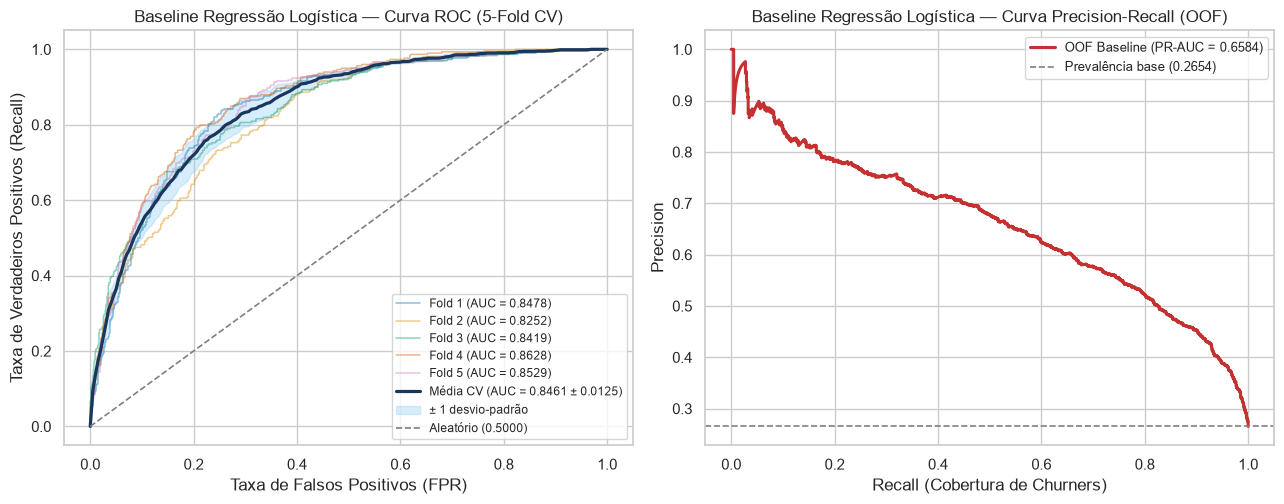

In [4]:
# Reproduzindo os 5 folds exatamente com o mesmo skf para plotar curvas por fold e OOF
skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
oof_proba = np.zeros(len(X_train), dtype=float)
mean_fpr = np.linspace(0, 1, 200)
tprs = []
fold_aucs = []

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

for fold_idx, (tr_idx, va_idx) in enumerate(skf.split(X_train, y_train), start=1):
    pipe = build_pipeline(clone(lr_model))
    pipe.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    val_p = pipe.predict_proba(X_train.iloc[va_idx])[:, 1]
    oof_proba[va_idx] = val_p

    fpr, tpr, _ = roc_curve(y_train.iloc[va_idx], val_p)
    fold_auc = auc(fpr, tpr)
    fold_aucs.append(fold_auc)
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
    axes[0].plot(fpr, tpr, lw=1.1, alpha=0.45, label=f"Fold {fold_idx} (AUC = {fold_auc:.4f})")

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
std_tpr = np.std(tprs, axis=0)
axes[0].plot(
    mean_fpr,
    mean_tpr,
    color="#1a365d",
    lw=2.3,
    label=f"Média CV (AUC = {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f})",
)
axes[0].fill_between(
    mean_fpr,
    np.maximum(mean_tpr - std_tpr, 0),
    np.minimum(mean_tpr + std_tpr, 1),
    color="#90cdf4",
    alpha=0.35,
    label="± 1 desvio-padrão",
)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", lw=1.2, label="Aleatório (0.5000)")
axes[0].set_title("Baseline Regressão Logística — Curva ROC (5-Fold CV)")
axes[0].set_xlabel("Taxa de Falsos Positivos (FPR)")
axes[0].set_ylabel("Taxa de Verdadeiros Positivos (Recall)")
axes[0].legend(loc="lower right", fontsize=8.5, frameon=True)

prec_oof, rec_oof, _ = precision_recall_curve(y_train, oof_proba)
axes[1].plot(
    rec_oof,
    prec_oof,
    color="#c53030",
    lw=2.2,
    label=f"OOF Baseline (PR-AUC = {lr_detail['oof_pr_auc']:.4f})",
)
baseline_rate = float(y_train.mean())
axes[1].axhline(baseline_rate, color="gray", linestyle="--", lw=1.2, label=f"Prevalência base ({baseline_rate:.4f})")
axes[1].set_title("Baseline Regressão Logística — Curva Precision-Recall (OOF)")
axes[1].set_xlabel("Recall (Cobertura de Churners)")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right", fontsize=9, frameon=True)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "baseline_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)


## 4. Prova Numérica: Trade-off Precision × Recall × Receita (Por que não 87%!) e Matriz de Confusão

Demonstramos na prática com as predições OOF do baseline o efeito financeiro e operacional de tentar
exigir *precision* altíssima (~85–87%) versus o limiar calibrado para negócio (`0.28`) e o padrão (`0.50`).


In [5]:
charges_train = X_train["MonthlyCharges"]
tradeoff_rows = []
for thr in [0.28, 0.50, 0.65, 0.75, 0.80, 0.85]:
    cls = classification_metrics(y_train, oof_proba, threshold=thr)
    biz = business_metrics(
        y_train,
        oof_proba,
        charges_train,
        threshold=thr,
        ltv_months=BUSINESS_LTV_MONTHS,
        retention_success_rate=BUSINESS_RETENTION_SUCCESS_RATE,
        action_cost=BUSINESS_ACTION_COST,
    )
    tradeoff_rows.append({
        "threshold": thr,
        "accuracy": round(cls["accuracy"], 4),
        "precision": round(cls["precision"], 4),
        "recall": round(cls["recall"], 4),
        "f1": round(cls["f1"], 4),
        "TP": biz["true_positives_caught"],
        "FP": biz["false_positives"],
        "net_retained_revenue_USD": round(float(biz["net_retained_revenue"]), 2),
        "roi": round(float(biz["roi"]), 2),
    })

display(pd.DataFrame(tradeoff_rows))


,threshold,accuracy,precision,recall,f1,TP,FP,net_retained_revenue_USD,roi
0,0.28,0.7599,0.5320,0.7900,0.6358,1181,1039,99188.82,1.49
1,0.50,0.8026,0.6543,0.5431,0.5936,812,429,82001.91,2.20
2,0.65,0.7893,0.7541,0.3057,0.4350,457,149,50340.51,2.77
3,0.75,0.7565,0.8436,0.1010,0.1804,151,28,19066.89,3.55
4,0.80,0.7421,0.9200,0.0308,0.0595,46,4,6166.65,4.11
5,0.85,0.7350,1.0000,0.0013,0.0027,2,0,278.67,4.64


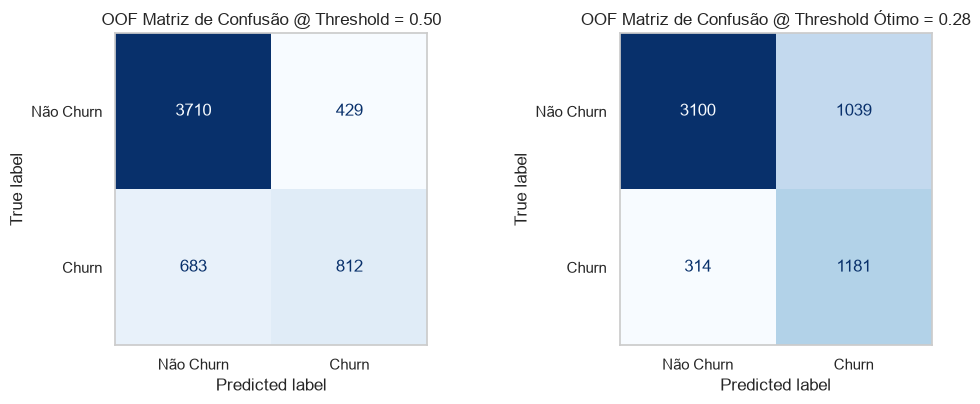

Baseline Holdout @ 0.50 -> AUC=0.8419 | PR-AUC=0.6338 | F1=0.6040 | Prec=0.6572 | Rec=0.5588 | Acc=0.8055 | NetRev=$20,045.34 | ROI=2.10x
Baseline Holdout @ 0.28 -> AUC=0.8419 | PR-AUC=0.6338 | F1=0.6226 | Prec=0.5177 | Rec=0.7807 | Acc=0.7488 | NetRev=$23,335.65 | ROI=1.38x


In [6]:
# Matrizes de confusão OOF: limiar 0.50 vs limiar ótimo 0.28
opt_thr = float(lr_detail["opt_threshold"])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for ax, thr, title in [
    (axes[0], 0.50, "OOF Matriz de Confusão @ Threshold = 0.50"),
    (axes[1], opt_thr, f"OOF Matriz de Confusão @ Threshold Ótimo = {opt_thr:.2f}"),
]:
    cm = confusion_matrix(y_train, (oof_proba >= thr).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=["Não Churn", "Churn"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d"
    )
    ax.grid(False)
    ax.set_title(title)

fig.tight_layout()
plt.show()
plt.close(fig)

# Avaliação de referência do baseline no Holdout (X_test)
lr_full = build_pipeline(clone(lr_model))
lr_full.fit(X_train, y_train)
lr_test_proba = lr_full.predict_proba(X_test)[:, 1]
test_charges = X_test["MonthlyCharges"]

for thr in (0.50, opt_thr):
    c = classification_metrics(y_test, lr_test_proba, threshold=thr)
    b = business_metrics(y_test, lr_test_proba, test_charges, threshold=thr)
    print(
        f"Baseline Holdout @ {thr:.2f} -> AUC={c['roc_auc']:.4f} | PR-AUC={c['pr_auc']:.4f} | "
        f"F1={c['f1']:.4f} | Prec={c['precision']:.4f} | Rec={c['recall']:.4f} | Acc={c['accuracy']:.4f} | "
        f"NetRev=${b['net_retained_revenue']:,.2f} | ROI={b['roi']:.2f}x"
    )
